# Kiểm thử độc lập: SpeechOcean762

**Mục tiêu:** kiểm tra B trên dữ liệu có nhãn chuyên gia ngoài L2-ARCTIC,
và đo A/B/C báo nhầm trên cùng các câu được cả 5 chuyên gia chấm đúng mọi âm.

SpeechOcean762 của **Junbo Zhang và cộng sự**, công bố tại **Interspeech 2021**: 5.000 bản thu tiếng Anh,
250 người nói có tiếng mẹ đẻ là tiếng Trung, gồm người lớn và trẻ em;
mỗi bản thu được 5 chuyên gia đánh giá độc lập.
[Bài báo](https://www.isca-archive.org/interspeech_2021/zhang21x_interspeech.pdf) ·
[OpenSLR 101, CC BY 4.0](https://www.openslr.org/101/) ·
[Repository chính thức](https://github.com/jimbozhang/speechocean762).

B chạy **toàn bộ 2.500 câu test chính thức**. A/C chạy **179 câu đối chứng**;
B dùng đúng 179 câu đó từ lượt test đầy đủ. Không train lại, chỉnh ngưỡng,
chọn mẫu theo dự đoán, hoặc gọi LLM/ai33. Mở notebook có thể xem ngay các output đã lưu.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib, json, os, subprocess, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Audio

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/external_speechocean762.json").is_file())
os.chdir(ROOT)
RESULTS = ROOT / 'data/generated/external/speechocean762/20261021T024600Z'
DATA = ROOT / "data/external/speechocean762/613968e3b0b789fc33936fb5eba1973176ba7d11"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True)
def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))
def read_rows(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()]
def sha(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Workspace:", ROOT)
print("Kết quả:", RESULTS)

Workspace: D:\NCC\MDD
Kết quả: D:\NCC\MDD\data\generated\external\speechocean762\20261021T024600Z


## 1. Tiêu chí đã chốt trước suy luận

Nhãn của từng chuyên gia: âm thường = **2, đúng**; `{PHONE}` = **1, đúng nhưng accent nặng**;
`(PHONE)` = **0, sai hoặc thiếu**; `[PHONE]` = âm thừa.
Một vị trí âm được gán lỗi nếu ít nhất 3/5 chuyên gia chấm 0. Một từ được gán lỗi
nếu ít nhất 3/5 chuyên gia ghi nhận âm 0 hoặc âm thừa trong từ đó.

Đối chứng nghiêm ngặt gồm mọi câu test mà **cả 5 chuyên gia đều chấm 2 cho mọi âm,
không có âm thừa**: 179 câu. Điểm 2 tổng hợp không đủ để kết luận cả 5 đồng ý;
script dùng nhãn gốc của từng người trong `scores-detail.json`.

Dùng nguyên pipeline demo: CPU FP32, 2 threads, greedy CTC và căn chỉnh âm chuẩn.
Chuỗi âm chuẩn lấy từ metadata chuyên gia SpeechOcean; đây là kiểm thử decoder
và alignment, chưa kiểm thử giao diện hoặc khả năng tạo âm chuẩn cho câu mới.
Chỉ bỏ số trọng âm 0/1/2; giữ nguyên AX/AH và các khác biệt âm khác.
Đây là phép đo theo vị trí âm chuẩn và nhãn đa số chuyên gia, **khác rubric F1 của L2-ARCTIC**.
Không có bản chép âm thực tế đầy đủ để tính PER hợp lệ cho bộ này.

In [2]:
protocol = read_json(DATA / "frozen_protocol.json")
source = read_json(DATA / "source-manifest.json")
assert len(protocol["official_test_ids"]) == 2500
assert len(protocol["strict_perfect_control_ids"]) == 179
assert sha(ROOT / protocol["study_config"]) == protocol["study_config_sha256"]
assert sha(DATA / "frozen_protocol.json") == source["frozen_protocol"]["sha256"]
assert sha(DATA / "audio_manifest.jsonl") == source["audio_manifest"]["sha256"]
display(pd.DataFrame([{
    "Dataset": protocol["dataset"], "Commit": protocol["commit"],
    "Test chính thức": protocol["test_count"], "Câu đối chứng": protocol["strict_perfect_control_count"],
    "ZIP SHA256": protocol["archive_sha256"], "Protocol SHA256": source["frozen_protocol"]["sha256"]
}]).T.rename(columns={0:"Giá trị"}))
audit_path = RESULTS / "audio_header_audit.json"
if audit_path.is_file():
    audio_audit = read_json(audit_path)
    assert audio_audit["all_header_constraints_pass"]
    print("WAV đã kiểm tra header:", audio_audit["readable_headers"])
    print("Thời lượng (giây):", audio_audit["duration_sec"])
environment_path = RESULTS / "execution_environment.json"
if environment_path.is_file():
    print("Phiên bản thư viện lúc kiểm thử:", read_json(environment_path)["packages"])

,Giá trị
Dataset,SpeechOcean762
Commit,613968e3b0b789fc33936fb5eba1973176ba7d11
Test chính thức,2500
Câu đối chứng,179
ZIP SHA256,7a38094f75a6e4bb36d182f0a6658626f23eeca573346f...
Protocol SHA256,8dc083e251dba9daab3ac9629257cf3fa71e21d6ff6d7c...


WAV đã kiểm tra header: 2500
Thời lượng (giây): {'min': 1.792, 'min_id': '030750170', 'max': 12.229, 'max_id': '096230020', 'median': 3.503, 'mean': 3.8754592, 'total': 9688.648}
Phiên bản thư viện lúc kiểm thử: {'torch': '2.7.1+cu126', 'transformers': '4.57.6', 'numpy': '2.2.6', 'scipy': '1.15.3', 'soundfile': '0.13.1', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'matplotlib': '3.11.2', 'pandas': '2.3.3'}


## 2. Lệnh tải, kiểm thử và chạy lại

Các cell mặc định chỉ đọc kết quả đã có. Bật biến tương ứng khi chủ động chạy lại.
Lượt suy luận mới ghi vào thư mục mới; `--resume` chỉ dùng với cùng dữ liệu, code,
checkpoint và protocol. Dữ liệu WAV/ZIP được lưu local trong `data/external/` và được bỏ qua bởi Git.

In [3]:
PYTHON = ROOT / ".venv/Scripts/python.exe"
PREPARE = [str(PYTHON), "-X", "utf8", "scripts/prepare_external_speechocean.py", "--download"]
TESTS = [str(PYTHON), "-m", "unittest", "discover", "-s", "tests", "-p", "test_external_speechocean.py", "-v"]
def evaluation_command(checkpoint, selection, output):
    return [str(PYTHON), "-X", "utf8", "scripts/evaluate_external_speechocean.py",
            "--checkpoint", checkpoint, "--selection", selection,
            "--threads", "2", "--output", str(output)]
COMMANDS = {
    "B-full": evaluation_command("windows-notebook-seed42-B-fold1", "full-test", RESULTS / "B-full"),
    "A-control": evaluation_command("windows-notebook-seed42-A", "perfect-control", RESULTS / "A-control"),
    "C-control": evaluation_command("windows-notebook-seed42-C-fold1", "perfect-control", RESULTS / "C-control")
}
for name, command in {"prepare": PREPARE, "tests": TESTS, **COMMANDS}.items():
    print(name + ":", subprocess.list2cmdline(command))

prepare: D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/prepare_external_speechocean.py --download
tests: D:\NCC\MDD\.venv\Scripts\python.exe -m unittest discover -s tests -p test_external_speechocean.py -v
B-full: D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/evaluate_external_speechocean.py --checkpoint windows-notebook-seed42-B-fold1 --selection full-test --threads 2 --output D:\NCC\MDD\data\generated\external\speechocean762\20261021T024600Z\B-full
A-control: D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/evaluate_external_speechocean.py --checkpoint windows-notebook-seed42-A --selection perfect-control --threads 2 --output D:\NCC\MDD\data\generated\external\speechocean762\20261021T024600Z\A-control
C-control: D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/evaluate_external_speechocean.py --checkpoint windows-notebook-seed42-C-fold1 --selection perfect-control --threads 2 --output D:\NCC\MDD\data\generated\external\speechocean762\20261021T024600Z\C-control


In [4]:
RUN_DOWNLOAD = False
RUN_TESTS = False
RUN_INFERENCE = False
if RUN_DOWNLOAD:
    subprocess.run(PREPARE, cwd=ROOT, check=True)
if RUN_TESTS:
    subprocess.run(TESTS, cwd=ROOT, check=True)
if RUN_INFERENCE:
    from datetime import datetime, timezone
    rerun = RESULTS.parent / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    for label, old in COMMANDS.items():
        command = old[:-1] + [str(rerun / label)]
        subprocess.run(command, cwd=ROOT, check=True)
    RESULTS = rerun
    FIGURES = RESULTS / "figures"
    FIGURES.mkdir(exist_ok=True)
    print("Lượt chạy mới:", rerun)
else:
    print("Đang xem kết quả cache; không tải, train, suy luận hay gọi dịch vụ bên ngoài.")

Đang xem kết quả cache; không tải, train, suy luận hay gọi dịch vụ bên ngoài.


## 3. Độ phủ và tính toàn vẹn của lượt chạy thật

In [5]:
reports = {label: read_json(RESULTS / label / "metrics.json") for label in COMMANDS}
history = {label: read_rows(RESULTS / label / "predictions.jsonl") for label in COMMANDS}
# Resume can preserve an earlier failed attempt before appending its retry.
rows = {label:list({r["utterance_id"]:r for r in attempts}.values()) for label,attempts in history.items()}
coverage = []
for label, report in reports.items():
    manifest = read_json(RESULTS / label / "manifest.json")
    ids = [r["utterance_id"] for r in rows[label]]
    expected = protocol["official_test_ids"] if label == "B-full" else protocol["strict_perfect_control_ids"]
    assert report["status"] == "completed" and report["failed_count"] == 0
    assert report["unprocessed_count"] == 0 and report["checkpoint_unchanged"]
    assert len(ids) == len(set(ids)) == len(expected) and set(ids) == set(expected)
    assert all(r["status"] == "ok" for r in rows[label])
    assert sha(RESULTS / label / "predictions.jsonl") == manifest["predictions_sha256"]
    assert sha(RESULTS / label / "metrics.json") == manifest["metrics_sha256"]
    total = Counter()
    for row in rows[label]:
        total.update(row["counts"])
    assert all(total[k] == v for k,v in report["counts"].items())
    checkpoint = Path(manifest["identity"]["checkpoint"])
    assert sha(checkpoint / "model.safetensors") == report["checkpoint_sha256_after"]["model.safetensors"]
    coverage.append({"Lượt":label, "Đã chạy":report["evaluated_count"], "Lỗi chạy":report["failed_count"],
                     "Số người nói":len({r["speaker_id"] for r in rows[label]}),
                     "Weights giữ nguyên":report["checkpoint_unchanged"],
                     "Bắt đầu UTC":manifest["started_at_utc"], "Xong UTC":manifest["finished_at_utc"]})
display(pd.DataFrame(coverage).set_index("Lượt"))
display(pd.DataFrame([{"Nhóm":group, "Câu":item["counts"]["utterances"],
                       "Âm chuẩn":item["counts"]["reference_phones"], "Từ":item["counts"]["reference_words"]}
                      for group,item in reports["B-full"]["groups"]["age"].items()]))
print("Prompt trùng chuẩn hoá với dữ liệu train L2-ARCTIC:",
      len(reports["B-full"]["overlap_audit"].get("normalized_text_overlap_ids", [])))

,Đã chạy,Lỗi chạy,Số người nói,Weights giữ nguyên,Bắt đầu UTC,Xong UTC
Lượt,,,,,,
B-full,2500,0,125,True,2026-10-21T02:46:26.528119+00:00,2026-10-21T03:03:30.244461+00:00
A-control,179,0,87,True,2026-10-21T02:47:27.321741+00:00,2026-10-21T02:48:59.021585+00:00
C-control,179,0,87,True,2026-10-21T02:47:27.284579+00:00,2026-10-21T02:48:59.339914+00:00


,Nhóm,Câu,Âm chuẩn,Từ
0,adult,1220,25752,8701
1,child,1280,21617,7266


Prompt trùng chuẩn hoá với dữ liệu train L2-ARCTIC: 0


## 4. B trên toàn bộ 2.500 câu test

Precision = phần cảnh báo khớp nhãn lỗi; recall = phần lỗi chuyên gia được phát hiện.
False positive ở mức từ dùng mẫu số là số từ được đa số chuyên gia chấp nhận.
Âm thừa được báo riêng, không đưa vào F1 theo vị trí âm chuẩn.

In [6]:
b = reports["B-full"]
metrics = b["metrics"]
detection = pd.DataFrame({"Âm (vị trí chuẩn)":metrics["canonical_position_detection"],
                          "Từ":metrics["word_detection"]}).T * 100
display(detection.rename(columns={"precision":"Precision %", "recall":"Recall %", "f1":"F1 %"}).round(2))
counts = b["counts"]
print("Nhãn lỗi đa số chuyên gia:", counts["position_tp"]+counts["position_fn"], "/", counts["reference_phones"], "vị trí âm;",
      counts["word_tp"]+counts["word_fn"], "/", counts["reference_words"], "từ.")
rate_names = {
    "Âm cả 5 chấm đúng nhưng model báo sai":"unanimous_correct_position_rejection_rate",
    "Âm cả 5 chấp nhận (kể cả accent) nhưng model báo sai":"unanimous_acceptable_position_rejection_rate",
    "Từ đa số chấp nhận nhưng model báo sai":"majority_accepted_word_false_positive_rate"
}
rate_table = pd.DataFrame([{"Chỉ số":name, "Số báo nhầm":metrics[key]["numerator"],
                            "Mẫu số":metrics[key]["denominator"], "Tỷ lệ %":100*metrics[key]["rate"]}
                           for name,key in rate_names.items()])
display(rate_table.set_index("Chỉ số").round(2))
print("Âm thừa dự đoán / 100 âm chuẩn:", round(metrics["predicted_insertions_per_100_reference_phones"], 2))
rate_table.to_csv(RESULTS / "B_false_alarm_summary.csv", index=False, encoding="utf-8-sig")

,Precision %,Recall %,F1 %
Âm (vị trí chuẩn),11.94,88.46,21.04
Từ,12.97,97.37,22.89


Nhãn lỗi đa số chuyên gia: 1950 / 47369 vị trí âm; 1295 / 15967 từ.


,Số báo nhầm,Mẫu số,Tỷ lệ %
Chỉ số,,,
Âm cả 5 chấm đúng nhưng model báo sai,8718,38495,22.65
Âm cả 5 chấp nhận (kể cả accent) nhưng model báo sai,10643,42118,25.27
Từ đa số chấp nhận nhưng model báo sai,8463,14672,57.68


Âm thừa dự đoán / 100 âm chuẩn: 5.83


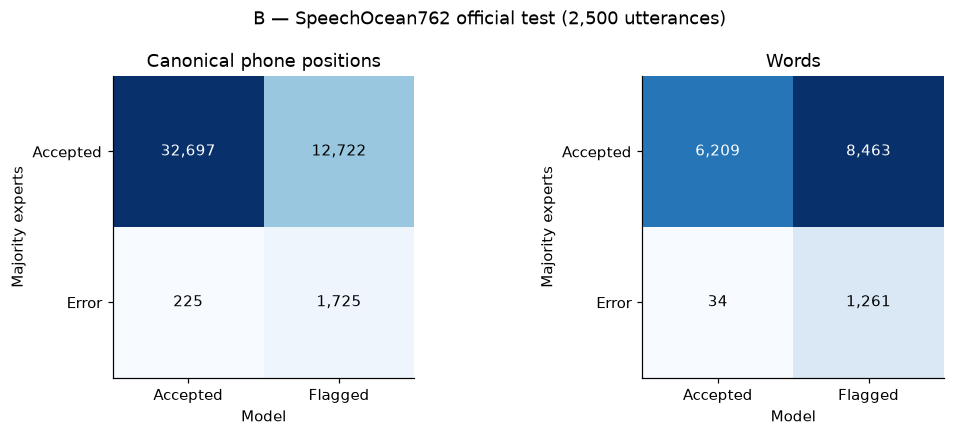

In [7]:
import numpy as np
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, prefix, title in zip(axes, ["position", "word"], ["Canonical phone positions", "Words"]):
    c = b["counts"]
    matrix = np.array([[c[prefix+"_tn"], c[prefix+"_fp"]], [c[prefix+"_fn"], c[prefix+"_tp"]]])
    ax.imshow(matrix, cmap="Blues")
    for (i,j), value in np.ndenumerate(matrix):
        ax.text(j,i,f"{value:,}",ha="center",va="center",color="white" if value > matrix.max()/2 else "black")
    ax.set(xticks=[0,1],xticklabels=["Accepted","Flagged"],yticks=[0,1],
           yticklabels=["Accepted","Error"],xlabel="Model",ylabel="Majority experts",title=title)
fig.suptitle("B — SpeechOcean762 official test (2,500 utterances)")
fig.tight_layout()
fig.savefig(FIGURES / "B_confusion.png", bbox_inches="tight")
display(fig)
plt.close(fig)

## 5. A/B/C trên cùng 179 câu được cả 5 chuyên gia chấm đúng

**A**: học trên source L2-ARCTIC; **B**: từ A, thích nghi với tiếng Anh của người Việt,
có replay source; **C**: từ A, học tiếp source với cùng số bước làm đối chứng.
A đã qua train source. So sánh A→B thể hiện tác động của bước thích nghi tiếng Việt.

Trong nhóm này, mọi cảnh báo đều không khớp đánh giá đúng của cả 5 chuyên gia.
Một câu dài có nhiều cơ hội xuất hiện cảnh báo, vì vậy xem cả tỷ lệ câu, từ và âm.

In [8]:
from scripts.evaluate_external_speechocean import derive_metrics
control_rows = {"A": rows["A-control"],
                "B": [r for r in rows["B-full"] if r["human"]["strict_perfect"]],
                "C": rows["C-control"]}
control = []
for model, subset in control_rows.items():
    assert {r["utterance_id"] for r in subset} == set(protocol["strict_perfect_control_ids"])
    counts = Counter()
    for row in subset:
        counts.update(row["counts"])
    m = derive_metrics(counts)
    control.append({"Model":model, "Câu":len(subset), "Câu bị báo sai":counts["strict_perfect_sentence_flags"],
                    "Câu bị báo sai %":100*m["strict_perfect_sentence_any_flag_rate"]["rate"],
                    "Từ bị báo sai":counts["strict_perfect_word_flags"], "Tổng từ":counts["strict_perfect_reference_words"],
                    "Từ bị báo sai %":100*m["strict_perfect_word_false_positive_rate"]["rate"],
                    "Âm bị báo sai":counts["strict_perfect_phone_rejections"], "Tổng âm":counts["strict_perfect_reference_phones"],
                    "Âm bị báo sai %":100*m["strict_perfect_phone_false_rejection_rate"]["rate"]})
control = pd.DataFrame(control).set_index("Model")
display(control.round(2))
print("179 câu đối chứng theo nhóm tuổi:", dict(Counter(r["age_group"] for r in control_rows["B"])))
print("Số người nói trong nhóm đối chứng:", len({r["speaker_id"] for r in control_rows["B"]}))
control.to_csv(RESULTS / "ABC_strict_control_comparison.csv", encoding="utf-8-sig")

,Câu,Câu bị báo sai,Câu bị báo sai %,Từ bị báo sai,Tổng từ,Từ bị báo sai %,Âm bị báo sai,Tổng âm,Âm bị báo sai %
Model,,,,,,,,,
A,179,167,93.30,401,972,41.26,515,2890,17.82
B,179,173,96.65,434,972,44.65,546,2890,18.89
C,179,166,92.74,395,972,40.64,499,2890,17.27


179 câu đối chứng theo nhóm tuổi: {'child': 109, 'adult': 70}
Số người nói trong nhóm đối chứng: 87


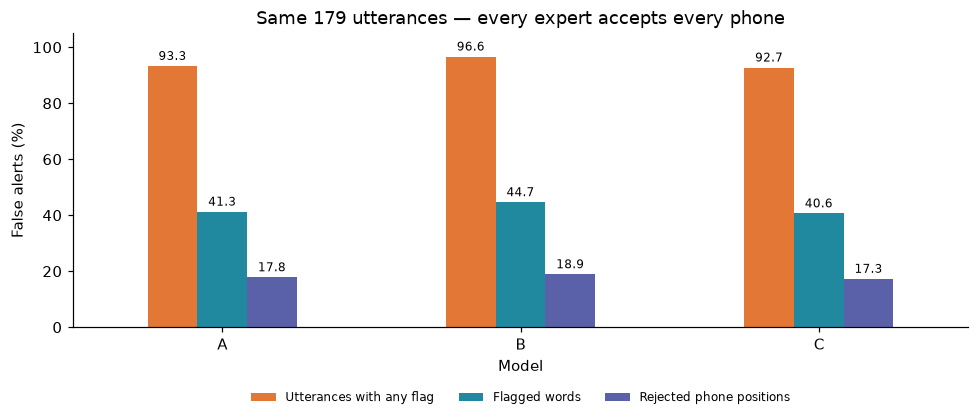

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
columns = ["Câu bị báo sai %", "Từ bị báo sai %", "Âm bị báo sai %"]
chart = control[columns].copy()
chart.columns = ["Utterances with any flag", "Flagged words", "Rejected phone positions"]
chart.plot.bar(ax=ax, rot=0, color=["#e37836", "#2089a0", "#5b61a8"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2, fontsize=8)
ax.set(title="Same 179 utterances — every expert accepts every phone", ylabel="False alerts (%)", ylim=(0, 105))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "ABC_false_alerts.png", bbox_inches="tight")
display(fig)
plt.close(fig)

## 6. Những âm và nhóm người nói dễ bị báo nhầm

In [10]:
pairs = Counter((e["kind"], e["expected_phone"], e["observed_phone"])
                for row in control_rows["B"] for e in row["events"])
common = pd.DataFrame([{"Loại":kind, "Âm chuẩn":expected, "Âm model nhận":observed, "Số lần":count}
                       for (kind,expected,observed),count in pairs.most_common(15)])
display(common)
print("Các khác biệt trên 179 câu đúng theo cả 5 chuyên gia; đây là bất đồng với nhãn, chưa xác định nguyên nhân.")
common.to_csv(RESULTS / "B_strict_control_common_mismatches.csv", index=False, encoding="utf-8-sig")

,Loại,Âm chuẩn,Âm model nhận,Số lần
0,addition,None,AH,37
1,substitution,DH,D,37
2,substitution,AH,AA,21
3,substitution,IH,IY,20
4,substitution,L,W,20
5,substitution,AH,AO,17
6,deletion,L,None,14
7,deletion,AH,None,14
8,substitution,DH,Z,13
9,deletion,R,None,10


Các khác biệt trên 179 câu đúng theo cả 5 chuyên gia; đây là bất đồng với nhãn, chưa xác định nguyên nhân.


,group,unanimous_correct_rejections,unanimous_correct_positions,false_rejection_percent
9,DH,829.0,1103.0,75.16
32,TH,113.0,179.0,63.13
38,Z,196.0,469.0,41.79
16,IH,1026.0,2574.0,39.86
20,L,563.0,1505.0,37.41
33,UH,134.0,367.0,36.51
2,AH,1197.0,3418.0,35.02
11,ER,177.0,561.0,31.55
27,R,290.0,975.0,29.74
1,AE,359.0,1226.0,29.28


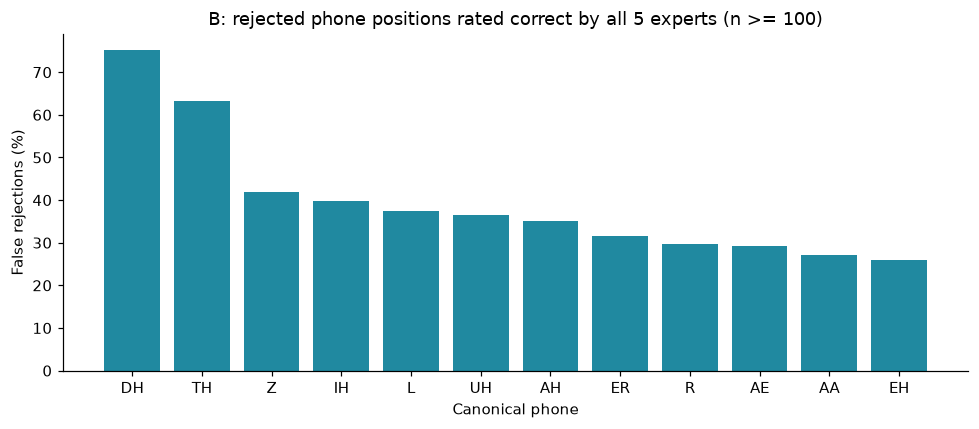

In [11]:
phones = pd.read_csv(RESULTS / "B-full/per_phone.csv").fillna(0)
phones = phones[phones["unanimous_correct_positions"] >= 100].copy()
phones["false_rejection_percent"] = 100*phones["unanimous_correct_rejections"]/phones["unanimous_correct_positions"]
worst = phones.sort_values(["false_rejection_percent", "group"], ascending=[False, True]).head(12)
display(worst[["group", "unanimous_correct_rejections", "unanimous_correct_positions", "false_rejection_percent"]].round(2))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(worst["group"], worst["false_rejection_percent"], color="#2089a0")
ax.set(title="B: rejected phone positions rated correct by all 5 experts (n >= 100)", ylabel="False rejections (%)", xlabel="Canonical phone")
fig.tight_layout()
fig.savefig(FIGURES / "B_phone_false_rejections.png", bbox_inches="tight")
display(fig)
plt.close(fig)

In [12]:
cohorts = pd.DataFrame([{"Nhóm":group, "Câu":entry["counts"]["utterances"],
    "Âm cả 5 chấm đúng":entry["counts"]["unanimous_correct_positions"],
    "Báo nhầm âm đúng %":100*entry["metrics"]["unanimous_correct_position_rejection_rate"]["rate"],
    "F1 vị trí âm %":100*entry["metrics"]["canonical_position_detection"]["f1"]}
    for group,entry in b["groups"]["age"].items()]).set_index("Nhóm")
display(cohorts.round(2))
print("Trẻ em: tuổi < 18; người lớn: tuổi >= 18. Không chọn nhóm theo kết quả model.")

,Câu,Âm cả 5 chấm đúng,Báo nhầm âm đúng %,F1 vị trí âm %
Nhóm,,,,
adult,1220,20591,20.89,26.27
child,1280,17904,24.66,14.80


Trẻ em: tuổi < 18; người lớn: tuổi >= 18. Không chọn nhóm theo kết quả model.


## 7. Nghe một ví dụ báo nhầm và xem lỗi cụ thể

Chọn xác định: câu đầu tiên theo utterance ID trong 179 câu đối chứng mà B có cảnh báo.
Đây là ví dụ minh hoạ; các chỉ số ở trên vẫn dùng toàn bộ mẫu đã chốt.
“Âm model nhận” là dự đoán CTC, không phải phiên âm người nói được chuyên gia xác nhận.

In [13]:
candidates = sorted([r for r in control_rows["B"] if r["events"]], key=lambda r:r["utterance_id"])
example = candidates[0] if candidates else sorted(control_rows["B"], key=lambda r:r["utterance_id"])[0]
display(Markdown(f"**{example['utterance_id']}** — {example['human']['reference_text']}"))
print("Canonical:", " ".join(example["human"]["canonical_phones"]))
print("Model B:  ", " ".join(example["predicted_phones"]))
display(Audio(filename=example["audio_path"], embed=True))
example_table = pd.DataFrame([{"Từ":example["human"]["words"][e["word_index"]], "Loại":e["kind"],
    "Âm chuẩn":e["expected_phone"], "Âm model nhận":e["observed_phone"],
    "Chuyên gia":"Cả 5 chấm đúng; không có âm thừa"} for e in example["events"]])
display(example_table)
example_table.to_csv(RESULTS / "example_B_false_alert.csv", index=False, encoding="utf-8-sig")

**000030049** — TWO EIGHT NINE ONE

Canonical: T UW EY T N AY N W AH N
Model B:   T UW EY T N AY N W AO N


,Từ,Loại,Âm chuẩn,Âm model nhận,Chuyên gia
0,ONE,substitution,AH,AO,Cả 5 chấm đúng; không có âm thừa


## 8. Diễn giải và giới hạn

Nhãn chuyên gia là chuẩn tham chiếu cho phép đo này. Khác biệt với nhãn có thể đến từ
nhận diện âm sai, căn chỉnh sai hoặc biến thể âm chuẩn khác giữa hai corpus.
Chạy test này chưa tách được đóng góp nhân quả của từng phần.

SpeechOcean762 là tiếng Anh của người có tiếng mẹ đẻ là tiếng Trung, có trẻ em;
**không phải bộ TTS hoặc bộ giọng bản ngữ chuẩn**. Kết quả không trực tiếp đo chất lượng
trên mọi voice TTS. Nó kiểm tra độc lập nhận xét model dễ cảnh báo nhầm khi chuyên gia
đánh giá âm đúng. Không dùng các nhãn test này để chỉnh model hoặc ngưỡng rồi báo lại cùng điểm.

F1 ở đây dùng rubric lỗi đa số theo vị trí chuẩn, không so trực tiếp với F1 L2-ARCTIC trước đây.
Câu/âm/từ trong cùng một người nói có tương quan; khoảng Wilson lưu trong metrics chỉ mang
tính mô tả, không chứng minh khác biệt có ý nghĩa thống kê.
Checkpoint A/B/C hiện tại đều đã qua train; BASE chỉ là backbone, chưa có đầu phoneme phù hợp.

In [14]:
value = control.loc["B"]
display(Markdown(
    f"B đã chạy **{b['evaluated_count']:,} câu test**, lỗi chạy **{b['failed_count']}**. "
    f"Trên **179 câu cả 5 chuyên gia chấm đúng**, B vẫn cảnh báo "
    f"**{int(value['Câu bị báo sai'])}/179 câu ({value['Câu bị báo sai %']:.2f}%)**, "
    f"**{int(value['Từ bị báo sai'])}/{int(value['Tổng từ'])} từ ({value['Từ bị báo sai %']:.2f}%)**. "
    "Cần đọc tỷ lệ này theo đánh giá chuyên gia và rubric đã mô tả; chưa thể coi cảnh báo của B là lỗi phát âm chắc chắn."
))
print("Predictions, per-phone/per-speaker/per-age/per-gender CSV và manifests:", RESULTS)
print("Biểu đồ PNG:", FIGURES)
(RESULTS.parent / "latest_results.json").write_text(
    json.dumps({"results":str(RESULTS.relative_to(ROOT)),
                "notebook":"notebooks/mdd_external_validation.ipynb", "status":"completed"}, indent=2),
    encoding="utf-8")

B đã chạy **2,500 câu test**, lỗi chạy **0**. Trên **179 câu cả 5 chuyên gia chấm đúng**, B vẫn cảnh báo **173/179 câu (96.65%)**, **434/972 từ (44.65%)**. Cần đọc tỷ lệ này theo đánh giá chuyên gia và rubric đã mô tả; chưa thể coi cảnh báo của B là lỗi phát âm chắc chắn.

Predictions, per-phone/per-speaker/per-age/per-gender CSV và manifests: D:\NCC\MDD\data\generated\external\speechocean762\20261021T024600Z
Biểu đồ PNG: D:\NCC\MDD\data\generated\external\speechocean762\20261021T024600Z\figures


160